# پیش‌بینی امتیاز احساسات کاربران با RoBERTa-base

در این نوت‌بوک یک مدل پنج‌کلاسه برای پیش‌بینی امتیاز کاربران آموزش داده می‌شود.

- **ورودی مدل:** ستون `full_text` (متن ترکیبی نظر)
- **هدف:** ستون `overall` با مقادیر ۱ تا ۵
- **مدل پایه:** `FacebookAI/roberta-base`
- **حداکثر طول توالی:** ۲۵۰ توکن
- **تقسیم داده:** ۸۰٪ آموزش، ۱۰٪ اعتبارسنجی و ۱۰٪ آزمون
- **سخت‌افزار:** اجرای آموزش روی GPU انویدیا در صورت فعال بودن CUDA

> نکته: این مسئله به‌صورت طبقه‌بندی چندکلاسه پیاده‌سازی شده است. برای سازگاری با مدل‌های Hugging Face، امتیازهای ۱ تا ۵ به برچسب‌های ۰ تا ۴ تبدیل می‌شوند و در خروجی دوباره به مقیاس ۱ تا ۵ برمی‌گردند.

با توجه به GPU چهارگیگابایتی RTX 2050 که قبلاً معرفی کرده بودی، کد در صورت تشخیص حافظه GPU حداکثر ۸ گیگابایت، به‌طور خودکار از **LoRA** برای ریزتنظیم کم‌مصرف‌تر RoBERTa-base استفاده می‌کند. در GPUهای پرحافظه‌تر، ریزتنظیم کامل مدل انجام می‌شود. در هر دو حالت، مدل پایه RoBERTa-base است.

> توجه: `FacebookAI/roberta-base` یک مدل ازپیش‌آموزش‌دیده برای زبان انگلیسی است. اگر متن‌های دیتاست فارسی یا چندزبانه‌اند، باید مدل پایه متناسب (برای مثال XLM-RoBERTa) انتخاب شود.

## ۱. نصب کتابخانه‌ها

این سلول PyTorch را دوباره نصب نمی‌کند تا نسخه CUDA نصب‌شده روی سیستم (برای مثال نسخه CUDA همراه PyTorch) بدون تغییر باقی بماند. پس از نصب یا به‌روزرسانی کتابخانه‌ها، در صورت درخواست Jupyter کرنل را Restart کن و اجرای نوت‌بوک را از ابتدا ادامه بده.

In [1]:
%pip install -U transformers datasets accelerate peft scikit-learn pandas numpy matplotlib seaborn safetensors

Note: you may need to restart the kernel to use updated packages.


## ۲. وارد کردن کتابخانه‌ها و بررسی GPU

این پروژه برای استفاده از GPU تنظیم شده است. اگر CUDA در دسترس نباشد، کد عمداً متوقف می‌شود تا آموزش ناخواسته و بسیار کند روی CPU انجام نشود.

In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc
import json
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    mean_absolute_error,
    classification_report,
    confusion_matrix,
)
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)
from peft import LoraConfig, TaskType, get_peft_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU/CUDA در دسترس نیست. نسخه GPU از PyTorch و درایور NVIDIA را بررسی کن "
        "و مطمئن شو Jupyter در همان محیطی اجرا می‌شود که CUDA در آن فعال است."
    )

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

try:
    BF16_SUPPORTED = torch.cuda.is_bf16_supported()
except Exception:
    BF16_SUPPORTED = False

USE_BF16 = bool(BF16_SUPPORTED)
USE_FP16 = not USE_BF16

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA version used by PyTorch: {torch.version.cuda}")
print(f"GPU: {GPU_NAME}")
print(f"GPU memory: {GPU_MEMORY_GB:.2f} GB")
print(f"Mixed precision: {'BF16' if USE_BF16 else 'FP16'}")

PyTorch version: 2.14.1+cu126
CUDA version used by PyTorch: 12.6
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.00 GB
Mixed precision: BF16


## ۳. تنظیمات پروژه و بارگذاری CSV

نام فایل را در `DATA_PATH` مطابق محل ذخیره دیتاست خودت تنظیم کن. اگر فایل در پوشه دیگری است، مسیر کامل را بنویس؛ برای مثال در ویندوز:

`DATA_PATH = r"D:\dataset\sentiment_ready_dataset.csv"`

کد ستون `full_text` را می‌خواند. برای سازگاری با نسخه‌های قبلی پیش‌پردازش، اگر نام ستون در فایل `full-text` باشد نیز آن را به `full_text` تغییر می‌دهد.

In [3]:
# مسیر فایل CSV را در صورت نیاز تغییر بده.
DATA_PATH = "sentiment_ready_dataset.csv"

MODEL_NAME = "FacebookAI/roberta-base"
MAX_LENGTH = 250
NUM_LABELS = 5

# در GPUهایی با حداکثر ۸ گیگابایت VRAM از LoRA استفاده می‌کنیم.
# این حالت برای GPU چهارگیگابایتی مناسب‌تر از Full Fine-tuning است.
USE_LORA = GPU_MEMORY_GB <= 8.0

OUTPUT_DIR = "./roberta_base_rating_output"
FINAL_MODEL_DIR = "./roberta_base_rating_model"

csv_path = Path(DATA_PATH)
if not csv_path.exists():
    raise FileNotFoundError(
        f"فایل دیتاست پیدا نشد: {csv_path.resolve()}\n"
        "مقدار DATA_PATH را در سلول تنظیمات اصلاح کن."
    )

df = pd.read_csv(csv_path, low_memory=False)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# پشتیبانی از نام‌گذاری full-text در فایل‌های قدیمی‌تر
if "full_text" not in df.columns and "full-text" in df.columns:
    df = df.rename(columns={"full-text": "full_text"})

required_columns = ["full_text", "overall"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        f"ستون‌های ضروری در CSV وجود ندارند: {missing_columns}\n"
        f"ستون‌های موجود: {df.columns.tolist()}"
    )

print("\nSample rows:")
display(df[["full_text", "overall"]].head())

Dataset shape: (830617, 15)
Columns: ['asin', 'reviewerID', 'reviewerName', 'unixReviewTime', 'brand', 'product_title', 'text_for_model', 'full-text', 'review_text_clean', 'summary_clean', 'review_date', 'verified_purchase', 'helpful_votes', 'style_attributes', 'overall']

Sample rows:


,full_text,overall
0,Cannot Learn. I have an older URC-WR7 remote a...,2
1,zero programming needed! Miracle!?. First time...,5
2,Works Good and programs easy.. Got them and on...,4
3,Same as TWC remote. I got tired of the remote ...,5
4,Good Quality Cord. After purchasing cheap cord...,5


## ۴. پاک‌سازی حداقلی و آماده‌سازی برچسب‌ها

برای RoBERTa از حذف stopword، stemming یا پاک‌کردن علائم نگارشی استفاده نمی‌کنیم؛ توکنایزر مدل باید متن طبیعی را دریافت کند. فقط ردیف‌هایی حذف می‌شوند که متن خالی یا امتیاز نامعتبر دارند.

امتیاز باید عدد صحیحی در بازه ۱ تا ۵ باشد.

In [4]:
ratings = pd.to_numeric(df["overall"], errors="coerce")
texts = df["full_text"].fillna("").astype(str).str.strip()

valid_rating = (
    ratings.notna()
    & ratings.between(1, 5)
    & np.isclose(ratings.fillna(0), np.round(ratings.fillna(0)))
)
valid_text = texts.ne("")
valid_rows = valid_rating & valid_text

before_count = len(df)
model_df = pd.DataFrame({
    "text": texts[valid_rows].values,
    "overall": np.round(ratings[valid_rows].astype(float)).astype(int).values,
})

# Hugging Face برای طبقه‌بندی پنج‌کلاسه برچسب‌های ۰ تا ۴ را دریافت می‌کند.
model_df["labels"] = model_df["overall"] - 1
model_df = model_df.reset_index(drop=True)

print(f"Rows before filtering: {before_count:,}")
print(f"Rows after filtering:  {len(model_df):,}")
print(f"Removed rows:          {before_count - len(model_df):,}")
print("\nRating distribution:")
display(
    model_df["overall"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis("overall")
    .to_frame("count")
)

if model_df.empty:
    raise ValueError("پس از حذف ردیف‌های نامعتبر، هیچ داده‌ای برای آموزش باقی نمانده است.")

class_counts = model_df["labels"].value_counts().reindex(range(NUM_LABELS), fill_value=0)
if (class_counts < 10).any():
    insufficient = {int(k + 1): int(v) for k, v in class_counts.items() if v < 10}
    raise ValueError(
        "برای تقسیم stratified به train/validation/test، حداقل ۱۰ نمونه از هر کلاس لازم است. "
        f"تعداد ناکافی در این کلاس‌ها: {insufficient}"
    )

Rows before filtering: 830,617
Rows after filtering:  830,617
Removed rows:          0

Rating distribution:


,count
overall,
1,82247
2,56288
3,80460
4,155143
5,456479


## ۵. تقسیم داده به Train، Validation و Test

داده‌ها به نسبت ۸۰/۱۰/۱۰ تقسیم می‌شوند. از `stratify` استفاده می‌کنیم تا نسبت کلاس‌های ۱ تا ۵ در هر بخش تا حد امکان مشابه کل دیتاست باقی بماند.

In [5]:
train_df, temp_df = train_test_split(
    model_df[["text", "labels"]],
    test_size=0.20,
    random_state=SEED,
    stratify=model_df["labels"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["labels"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train:      {len(train_df):,} ({len(train_df)/len(model_df):.1%})")
print(f"Validation: {len(val_df):,} ({len(val_df)/len(model_df):.1%})")
print(f"Test:       {len(test_df):,} ({len(test_df)/len(model_df):.1%})")

split_dist = pd.DataFrame({
    "train": train_df["labels"].value_counts(normalize=True),
    "validation": val_df["labels"].value_counts(normalize=True),
    "test": test_df["labels"].value_counts(normalize=True),
}).reindex(range(NUM_LABELS))
split_dist.index = [1, 2, 3, 4, 5]
split_dist.index.name = "overall"
display(split_dist.fillna(0).round(3))

Train:      664,493 (80.0%)
Validation: 83,062 (10.0%)
Test:       83,062 (10.0%)


,train,validation,test
overall,,,
1,0.099,0.099,0.099
2,0.068,0.068,0.068
3,0.097,0.097,0.097
4,0.187,0.187,0.187
5,0.550,0.550,0.550


## ۶. بارگذاری توکنایزر و توکن‌سازی متن‌ها

توکنایزر متن را به شناسه‌های عددی تبدیل می‌کند. `MAX_LENGTH=250` یعنی هر ورودی حداکثر ۲۵۰ توکن خواهد داشت؛ متن‌های بلندتر بریده و متن‌های کوتاه‌تر هنگام تشکیل batch به‌صورت پویا padding می‌شوند.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )

def make_tokenized_dataset(frame, split_name):
    hf_dataset = Dataset.from_pandas(
        frame[["text", "labels"]],
        preserve_index=False,
    )
    tokenized = hf_dataset.map(
        tokenize_batch,
        batched=True,
        batch_size=256,
        remove_columns=["text"],
        desc=f"Tokenizing {split_name}",
    )
    return tokenized

train_dataset = make_tokenized_dataset(train_df, "train")
val_dataset = make_tokenized_dataset(val_df, "validation")
test_dataset = make_tokenized_dataset(test_df, "test")

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=None,
)

print(train_dataset)
print("Example token count:", len(train_dataset[0]["input_ids"]))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

c:\Users\alijm\anaconda3\envs\py311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alijm\.cache\huggingface\hub\models--FacebookAI--roberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizing train:   0%|          | 0/664493 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/83062 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/83062 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 664493
})
Example token count: 136


## ۷. بارگذاری RoBERTa-base و انتخاب روش Fine-tuning

مدل از نوع `AutoModelForSequenceClassification` با پنج خروجی است. برای GPU کم‌حافظه، LoRA فقط پارامترهای سازگار (لایه‌های Query و Value و سر طبقه‌بندی) را آموزش می‌دهد و وزن‌های اصلی RoBERTa را ثابت نگه می‌دارد؛ این روش همچنان از RoBERTa-base استفاده می‌کند، اما تمام وزن‌های مدل را بازآموزی نمی‌کند.

In [7]:
id2label = {
    0: "1_star",
    1: "2_star",
    2: "3_star",
    3: "4_star",
    4: "5_star",
}
label2id = {name: idx for idx, name in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
    problem_type="single_label_classification",
)

if USE_LORA:
    print("Low-VRAM GPU detected: enabling LoRA fine-tuning.")
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8,
        lora_alpha=16,
        lora_dropout=0.10,
        target_modules=["query", "value"],
        modules_to_save=["classifier"],
        bias="none",
    )
    model = get_peft_model(model, lora_config)
    # برای سازگاری با gradient checkpointing در مدل‌های دارای پارامترهای منجمد
    if hasattr(model, "enable_input_require_grads"):
        model.enable_input_require_grads()
else:
    print("GPU memory is sufficient: full fine-tuning will be used.")

if hasattr(model, "config"):
    model.config.use_cache = False

if USE_LORA and hasattr(model, "print_trainable_parameters"):
    model.print_trainable_parameters()

c:\Users\alijm\anaconda3\envs\py311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alijm\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Low-VRAM GPU detected: enabling LoRA fine-tuning.
trainable params: 889,349 || all params: 125,538,826 || trainable%: 0.7084


## ۸. تعریف معیارهای ارزیابی و تنظیمات آموزش

معیارهای Accuracy، Precision، Recall، Macro-F1 و MAE محاسبه می‌شوند. برای انتخاب بهترین checkpoint، از Macro-F1 استفاده می‌کنیم تا عملکرد مدل روی هر پنج کلاس دیده شود؛ MAE نیز نشان می‌دهد پیش‌بینی‌ها به‌طور متوسط چند ستاره با امتیاز واقعی فاصله دارند.

تنظیمات اولیه برای GPU چهارگیگابایتی محافظه‌کارانه‌اند: batch size برابر ۱، انباشت گرادیان ۸ مرحله‌ای، gradient checkpointing و mixed precision.

In [16]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    predictions = np.argmax(logits, axis=-1)

    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0,
    )
    weighted_f1 = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0,
    )[2]

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "mae_stars": mean_absolute_error(labels + 1, predictions + 1),
    }

# تنظیمات محافظه‌کارانه برای GPU با VRAM محدود
TRAIN_BATCH_SIZE = 1
EVAL_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=2,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=0.10,
    lr_scheduler_type="linear",
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    fp16=USE_FP16,
    bf16=USE_BF16,
    optim="adafactor",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    eval_accumulation_steps=1,
    dataloader_num_workers=0,
    dataloader_pin_memory=True,
    report_to="none",
    seed=SEED,
    data_seed=SEED
)

print("LoRA enabled:", USE_LORA)
print("Effective batch size:", TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)

LoRA enabled: True
Effective batch size: 8


## ۹. آموزش مدل

آموزش روی GPU انجام می‌شود. اگر با وجود تنظیمات کم‌مصرف خطای CUDA Out Of Memory دریافت شد، ابتدا سایر برنامه‌های GPU را ببند و کرنل را Restart کن. در صورت تکرار خطا، `MAX_LENGTH` را مثلاً به ۱۹۲ کاهش بده یا از GPU با حافظه بیشتر استفاده کن.

In [17]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

gc.collect()
torch.cuda.empty_cache()

train_result = trainer.train()
print(train_result)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Mae Stars
1,4.205788,0.607397,0.762804,0.640645,0.627099,0.628302,0.752507,0.286665
2,5.004209,0.585552,0.766464,0.649376,0.638373,0.642020,0.760107,0.275457


TrainOutput(global_step=166124, training_loss=5.010378575417438, metrics={'train_runtime': 75036.6759, 'train_samples_per_second': 17.711, 'train_steps_per_second': 2.214, 'total_flos': 8.669970183207194e+16, 'train_loss': 5.010378575417438, 'epoch': 2.0})


## ۱۰. ذخیره مدل و توکنایزر

اگر LoRA فعال باشد، پوشه مدل شامل adapter آموزش‌دیده و تنظیمات آن خواهد بود؛ برای استفاده مجدد، مدل پایه RoBERTa-base نیز لازم است و از شناسه `FacebookAI/roberta-base` بارگذاری می‌شود. در حالت Full Fine-tuning، وزن‌های کامل مدل ذخیره خواهند شد.

In [18]:
Path(FINAL_MODEL_DIR).mkdir(parents=True, exist_ok=True)
trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

with open(Path(FINAL_MODEL_DIR) / "training_config.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "base_model": MODEL_NAME,
            "max_length": MAX_LENGTH,
            "num_labels": NUM_LABELS,
            "rating_mapping": {str(i): i - 1 for i in range(1, 6)},
            "use_lora": USE_LORA,
            "gpu_name": GPU_NAME,
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f"Model and tokenizer saved to: {Path(FINAL_MODEL_DIR).resolve()}")

Model and tokenizer saved to: D:\VS\AI\P-DL\roberta_base_rating_model


## ۱۱. ارزیابی نهایی روی Test Set

داده آزمون تا این مرحله در آموزش یا انتخاب checkpoint دخالت نداشته است. این بخش معیارهای نهایی، گزارش هر کلاس و ماتریس درهم‌ریختگی را محاسبه می‌کند.

In [19]:
test_metrics = trainer.evaluate(eval_dataset=test_dataset, metric_key_prefix="test")
print("Test metrics:")
for key, value in test_metrics.items():
    if isinstance(value, (int, float, np.number)):
        print(f"{key}: {value:.4f}")

prediction_output = trainer.predict(test_dataset, metric_key_prefix="test")
logits = prediction_output.predictions
if isinstance(logits, tuple):
    logits = logits[0]

predicted_labels = np.argmax(logits, axis=-1)
probabilities = torch.softmax(torch.tensor(logits), dim=-1).numpy()
confidence = probabilities.max(axis=1)
true_labels = prediction_output.label_ids

print("\nClassification report:")
print(
    classification_report(
        true_labels,
        predicted_labels,
        labels=[0, 1, 2, 3, 4],
        target_names=["1 star", "2 stars", "3 stars", "4 stars", "5 stars"],
        zero_division=0,
    )
)

results_df = pd.DataFrame({
    "full_text": test_df["text"].values,
    "actual_overall": true_labels + 1,
    "predicted_overall": predicted_labels + 1,
    "prediction_confidence": confidence,
})
results_df.to_csv("roberta_test_predictions.csv", index=False, encoding="utf-8-sig")

with open("roberta_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump({k: float(v) for k, v in test_metrics.items() if isinstance(v, (int, float, np.number))}, f, indent=2)

print("Saved: roberta_test_predictions.csv")
print("Saved: roberta_test_metrics.json")

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Mae Stars
5.004209,0.582943,2,0.767138,0.649412,0.637820,0.641721,0.760647,0.272917


Test metrics:
test_loss: 0.5829
test_accuracy: 0.7671
test_macro_precision: 0.6494
test_macro_recall: 0.6378
test_macro_f1: 0.6417
test_weighted_f1: 0.7606
test_mae_stars: 0.2729



Classification report:
              precision    recall  f1-score   support

      1 star       0.71      0.80      0.75      8225
     2 stars       0.47      0.40      0.43      5629
     3 stars       0.56      0.52      0.54      8046
     4 stars       0.63      0.55      0.59     15514
     5 stars       0.88      0.92      0.90     45648

    accuracy                           0.77     83062
   macro avg       0.65      0.64      0.64     83062
weighted avg       0.76      0.77      0.76     83062

Saved: roberta_test_predictions.csv
Saved: roberta_test_metrics.json


## ۱۲. ماتریس درهم‌ریختگی و تحلیل نتایج

ماتریس درهم‌ریختگی نشان می‌دهد مدل امتیاز هر کلاس را با چه کلاس‌هایی اشتباه گرفته است. چون امتیازها ترتیبی هستند، اشتباه ۴ با ۵ از نظر فاصله با اشتباه ۱ با ۵ یکسان نیست؛ به همین دلیل MAE نیز در کنار Accuracy و F1 گزارش می‌شود.

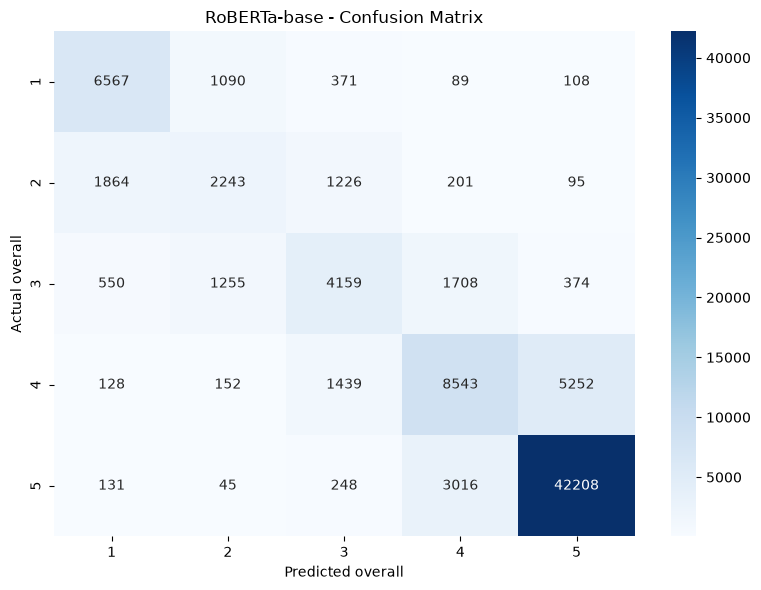

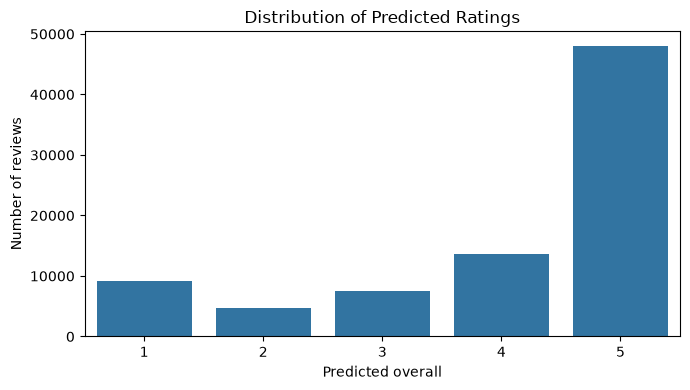

In [20]:
cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1, 2, 3, 4])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5],
)
plt.xlabel("Predicted overall")
plt.ylabel("Actual overall")
plt.title("RoBERTa-base - Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(x="predicted_overall", data=results_df, order=[1, 2, 3, 4, 5])
plt.xlabel("Predicted overall")
plt.ylabel("Number of reviews")
plt.title("Distribution of Predicted Ratings")
plt.tight_layout()
plt.show()

## ۱۳. تابع پیش‌بینی برای نظرهای جدید

پس از آموزش، می‌توانی متن یک یا چند نظر جدید را به تابع زیر بدهی. خروجی شامل امتیاز پیش‌بینی‌شده از ۱ تا ۵ و اطمینان مدل برای همان کلاس است.

In [21]:
def predict_rating(texts, batch_size=1):
    """Predict 1-to-5 ratings for a string or a list of review texts."""
    if isinstance(texts, str):
        texts = [texts]
    if not isinstance(texts, (list, tuple)) or not all(isinstance(t, str) for t in texts):
        raise TypeError("texts باید یک رشته یا فهرستی از رشته‌ها باشد.")

    model_for_inference = trainer.model
    model_for_inference.eval()
    predictions = []

    for start in range(0, len(texts), batch_size):
        batch_texts = [t if t.strip() else "[EMPTY REVIEW]" for t in texts[start:start + batch_size]]
        encoded = tokenizer(
            batch_texts,
            truncation=True,
            max_length=MAX_LENGTH,
            padding=True,
            return_tensors="pt",
        )
        encoded = {key: value.to(DEVICE) for key, value in encoded.items()}

        with torch.inference_mode():
            outputs = model_for_inference(**encoded)
            probs = torch.softmax(outputs.logits, dim=-1)
            conf, pred = probs.max(dim=-1)

        for rating, score in zip(pred.cpu().tolist(), conf.cpu().tolist()):
            predictions.append({
                "predicted_overall": int(rating + 1),
                "confidence": float(score),
            })

    return pd.DataFrame(predictions)

# نمونه؛ متن دلخواه خودت را جایگزین کن.
example_reviews = [
    "This product is excellent and works exactly as expected.",
    "Very poor quality. It stopped working after two days.",
]

display(predict_rating(example_reviews))

,predicted_overall,confidence
0,5,0.992329
1,1,0.978775


## ۱۴. نکات مهم در تفسیر خروجی

1. Accuracy به‌تنهایی برای این مسئله کافی نیست؛ Macro-F1 و گزارش هر کلاس را نیز بررسی کن.
2. چون امتیازهای ۱ تا ۵ ماهیت ترتیبی دارند، MAE کمک می‌کند فاصله پیش‌بینی از امتیاز واقعی را بفهمیم.
3. اگر تعداد نمونه‌های کلاس‌ها بسیار نامتوازن باشد، ممکن است لازم باشد در آزمایش بعدی از وزن‌دهی کلاس‌ها یا روش نمونه‌برداری استفاده کنیم.
4. `MAX_LENGTH=250` به این معناست که بخش انتهایی نظراتی که بیش از ۲۵۰ توکن دارند بریده می‌شود.
5. تنظیم خودکار LoRA برای GPUهای حداکثر ۸ گیگابایت، به‌منظور کاهش حافظه موردنیاز است؛ این روش با fine-tuning کامل همه وزن‌های RoBERTa یکسان نیست.
6. نتیجه نهایی فقط پس از اجرای آموزش روی فایل CSV واقعی قابل گزارش است.